# 📐 Polynomial Regression from Scratch

**Goal:** Fit a non-linear relationship by mapping features to a higher-degree polynomial space, then applying Linear Regression.

---

## 1. Algorithm Intuition

When the data shows a curved trend, a straight line is insufficient. The key insight is:

> **Polynomial Regression is Linear Regression on transformed features.**

Given a single feature $x$, we create a new feature matrix:

$$\phi(x) = [x, x^2, x^3, \ldots, x^d]$$

Then we fit a linear model on $\phi(x)$:

$$\hat{y} = w_1 x + w_2 x^2 + \ldots + w_d x^d + b$$

**Variable glossary:**
| Symbol | Meaning |
|--------|---------|
| $d$ | polynomial degree |
| $\phi(x)$ | feature-expanded matrix |
| $m$ | number of training examples |
| $\alpha$ | learning rate |
| `num_iters` | gradient-descent iterations |
| `J_history` | cost per iteration |

**Key risk:** High-degree polynomials can **overfit** the training data and perform poorly on new data.

---

## 2. Cost & Gradients

Identical to Linear Regression once features are expanded:

$$J(\mathbf{w}, b) = \frac{1}{2m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})^2$$

$$\frac{\partial J}{\partial \mathbf{w}} = \frac{1}{m} \Phi^T (\hat{y} - y), \qquad \frac{\partial J}{\partial b} = \frac{1}{m} \sum (\hat{y}^{(i)} - y^{(i)})$$


## 3. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
plt.style.use('seaborn-v0_8-whitegrid')

## 4. Synthetic Data — Cubic Relationship

In [2]:
# True relationship: y = 0.5x^3 - 2x^2 + x + 3 + noise
m = 150
X_raw = np.linspace(-3, 4, m)                      # 1-D feature, shape (m,)
y_all = 0.5 * X_raw**3 - 2 * X_raw**2 + X_raw + 3 + np.random.randn(m) * 2

# Reshape to column vector for matrix ops
X_raw = X_raw.reshape(-1, 1)                       # shape (m, 1)

print(f"X_raw shape: {X_raw.shape}")
print(f"y_all shape: {y_all.shape}")

X_raw shape: (150, 1)
y_all shape: (150,)


## 5. Polynomial Feature Expansion

In [3]:
def polynomial_features(X, degree):
    """
    Expand a single-column feature matrix X to polynomial features.

    Example (degree=3): X → [x, x^2, x^3]

    Parameters
    ----------
    X      : ndarray, shape (m, 1)  — original single feature
    degree : int                    — maximum polynomial degree

    Returns
    -------
    Phi : ndarray, shape (m, degree)
    """
    m = X.shape[0]
    Phi = np.ones((m, degree))       # will fill each column
    for d in range(1, degree + 1):
        Phi[:, d - 1] = X[:, 0] ** d
    return Phi

# Quick shape check
degree = 3
Phi_test = polynomial_features(X_raw, degree)
print(f"Expanded feature matrix shape: {Phi_test.shape}   (m x degree)")
print("First 3 rows:")
print(Phi_test[:3])

Expanded feature matrix shape: (150, 3)   (m x degree)
First 3 rows:
[[ -3.           9.         -27.        ]
 [ -2.95302013   8.72032791 -25.7513039 ]
 [ -2.90604027   8.44507004 -24.54171361]]


## 6. Train / Test Split and Normalisation

In [4]:
def train_test_split(X, y, test_ratio=0.2, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    split = int(len(y) * (1 - test_ratio))
    return X[idx[:split]], X[idx[split:]], y[idx[:split]], y[idx[split:]]

def normalize(X_train, X_test):
    mu    = X_train.mean(axis=0)
    sigma = X_train.std(axis=0)
    sigma[sigma == 0] = 1
    return (X_train - mu) / sigma, (X_test - mu) / sigma, mu, sigma

# ---- Degree 3 polynomial ----
Phi_all = polynomial_features(X_raw, degree=3)
Phi_train, Phi_test, y_train, y_test = train_test_split(Phi_all, y_all)
Phi_train_n, Phi_test_n, mu_p, sigma_p = normalize(Phi_train, Phi_test)

# Keep raw X for plotting
X_train_raw, X_test_raw, _, _ = train_test_split(X_raw, y_all)

print(f"Phi_train shape: {Phi_train_n.shape}")

Phi_train shape: (120, 3)


## 7. Reusable Linear Regression Core

In [5]:
def compute_cost(X, y, w, b):
    m = X.shape[0]
    errors = X @ w + b - y
    return np.sum(errors ** 2) / (2 * m)

def compute_gradient(X, y, w, b):
    m = X.shape[0]
    errors = X @ w + b - y
    dw = (X.T @ errors) / m
    db = np.sum(errors) / m
    return dw, db

def gradient_descent(X, y, alpha, num_iters):
    n = X.shape[1]
    w = np.zeros(n)
    b = 0.0
    J_history = []
    for i in range(num_iters):
        dw, db = compute_gradient(X, y, w, b)
        w = w - alpha * dw
        b = b - alpha * db
        J_history.append(compute_cost(X, y, w, b))
    return w, b, J_history

## 8. Train on Degree-3 Polynomial

In [6]:
alpha     = 0.05
num_iters = 5000

w3, b3, J_history3 = gradient_descent(Phi_train_n, y_train, alpha, num_iters)
print(f"Final train cost (degree 3): {J_history3[-1]:.4f}")

Final train cost (degree 3): 1.9265


## 9. Visualise Fit for Different Degrees

We compare degree 1 (underfitting), degree 3 (good fit), and degree 10 (overfitting).

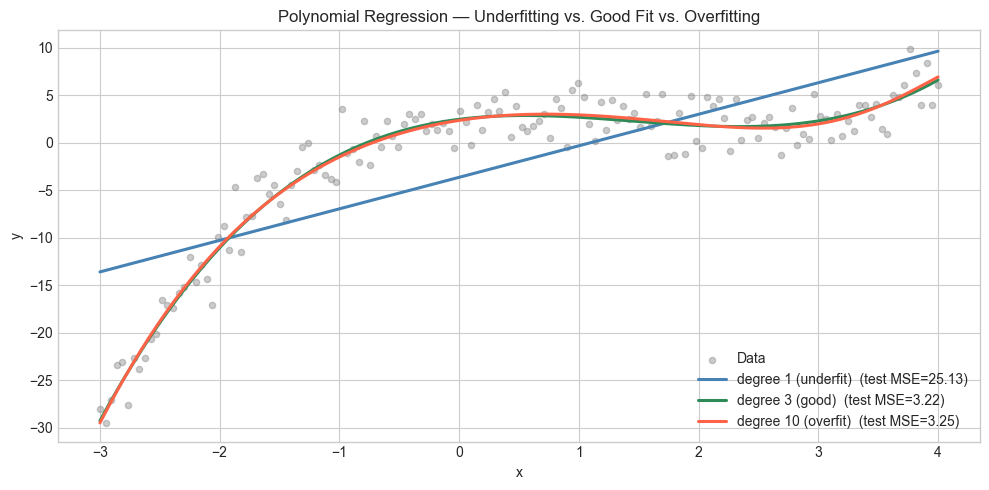

In [7]:
def fit_degree(X_raw, y, degree, alpha=0.05, num_iters=5000, seed=42):
    """Full pipeline: expand → split → normalise → train."""
    Phi = polynomial_features(X_raw, degree)
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    split = int(len(y) * 0.8)
    tr, te = idx[:split], idx[split:]
    Phi_tr, Phi_te = Phi[tr], Phi[te]
    y_tr, y_te = y[tr], y[te]

    mu    = Phi_tr.mean(axis=0)
    sigma = Phi_tr.std(axis=0)
    sigma[sigma == 0] = 1
    Phi_tr_n = (Phi_tr - mu) / sigma
    Phi_te_n = (Phi_te - mu) / sigma

    w, b, _ = gradient_descent(Phi_tr_n, y_tr, alpha, num_iters)

    # Build a smooth prediction curve over the full x range
    x_plot = np.linspace(X_raw.min(), X_raw.max(), 300).reshape(-1, 1)
    Phi_plot = polynomial_features(x_plot, degree)
    Phi_plot_n = (Phi_plot - mu) / sigma
    y_plot = Phi_plot_n @ w + b

    # Test MSE
    y_pred_te = Phi_te_n @ w + b
    test_mse = np.mean((y_pred_te - y_te) ** 2)
    return x_plot, y_plot, test_mse

degrees = [1, 3, 10]
colors  = ['steelblue', 'seagreen', 'tomato']
labels  = ['degree 1 (underfit)', 'degree 3 (good)', 'degree 10 (overfit)']

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(X_raw, y_all, alpha=0.4, color='gray', s=20, label='Data')

for d, col, lab in zip(degrees, colors, labels):
    x_pl, y_pl, mse = fit_degree(X_raw, y_all, degree=d)
    ax.plot(x_pl, y_pl, color=col, linewidth=2.2, label=f'{lab}  (test MSE={mse:.2f})')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Polynomial Regression — Underfitting vs. Good Fit vs. Overfitting')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Cost History

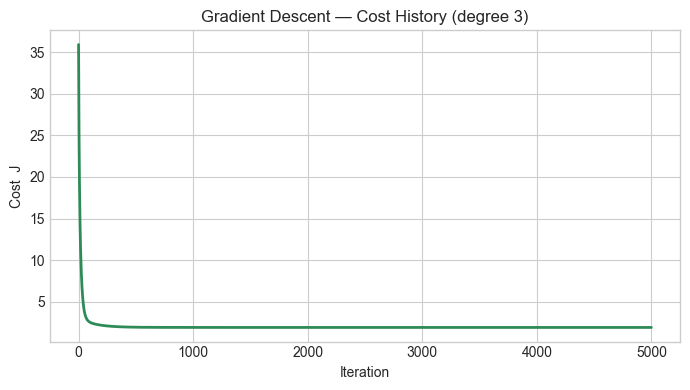

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(J_history3, color='seagreen', linewidth=2)
plt.xlabel('Iteration')
plt.ylabel('Cost  J')
plt.title('Gradient Descent — Cost History (degree 3)')
plt.tight_layout()
plt.show()

## 11. Evaluation Metrics

In [9]:
def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = Phi_train_n @ w3 + b3
y_pred_test  = Phi_test_n  @ w3 + b3

for split_name, y_true, y_pred in [('Train', y_train, y_pred_train),
                                    ('Test',  y_test,  y_pred_test)]:
    mse = np.mean((y_true - y_pred) ** 2)
    r2  = r2_score(y_true, y_pred)
    print(f"{split_name:6s} | MSE={mse:.3f}  RMSE={mse**0.5:.3f}  R²={r2:.4f}")

Train  | MSE=3.853  RMSE=1.963  R²=0.9491
Test   | MSE=3.219  RMSE=1.794  R²=0.9316


## 12. Observations and Limitations

### What we observed
- **Degree 1** misses the curve → high bias (underfitting).
- **Degree 3** captures the cubic trend well → low bias, reasonable variance.
- **Degree 10** fits the training points almost perfectly but oscillates wildly → high variance (overfitting).

### Limitations
| Limitation | Description |
|------------|-------------|
| **Overfitting** | Without regularisation, high-degree models memorise noise. |
| **Feature explosion** | With multiple input features, all cross-terms grow combinatorially. |
| **Slow gradient descent** | High-degree, unnormalised features cause very slow convergence. |
| **Numerical instability** | $x^{10}$ for large $x$ can overflow in float32; normalisation mitigates this. |
| **Degree selection** | We chose degree 3 by visualising; in practice use cross-validation. |
